# Regressionsbaum 

In [48]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn import tree

from vnw.defines.defines import (
    TESTSET_PATH,
    TRAINSET_PATH,
    VALSET_PATH,
)
from vnw.load_data.load_prepare_data import LoadPrepareData
from vnw.load_data.set_loader import SetLoader
from vnw.ml.dataset_loader import TrainTestValSplitter
from vnw.ml.feature_engineer import FeatureEngineer

In [49]:
df_raw = LoadPrepareData().load_and_prepare_data()

df = df_raw[
    [
        "Category",
        "Subcategory",
        "ProductLine",
        "Model",
        "OrderQuantity",
    ]
].copy()

df_agg = df.groupby(
    ["Category", "Subcategory", "ProductLine", "Model"], as_index=False
).agg({"OrderQuantity": "sum"})
df_agg

,Category,Subcategory,ProductLine,Model,OrderQuantity
0,Accessories,Bike Racks,S,Hitch Rack - 4-Bike,3166
1,Accessories,Bike Stands,M,All-Purpose Bike Stand,249
2,Accessories,Bottles and Cages,M,Mountain Bottle Cage,2025
3,Accessories,Bottles and Cages,R,Road Bottle Cage,1712
4,Accessories,Bottles and Cages,S,Water Bottle,6815
...,...,...,...,...,...
87,Components,Wheels,R,HL Road Front Wheel,567
88,Components,Wheels,R,HL Road Rear Wheel,92
89,Components,Wheels,R,LL Road Rear Wheel,866
90,Components,Wheels,R,ML Road Front Wheel,530


In [50]:
TrainTestValSplitter(df_agg).get_splits_save_as_parquet()
set_loader = SetLoader(TRAINSET_PATH, TESTSET_PATH, VALSET_PATH)
trainset, testset, valset = set_loader.load_sets()

Trainset: (64, 5)
Testset: (14, 5)
Valset: (14, 5)


In [51]:
FEATURES = [
    "Category",
    "Subcategory",
    "ProductLine",
    "Model",
]

TARGET = "OrderQuantity"


X_train = trainset[FEATURES]
y_train = trainset[TARGET]

X_val = valset[FEATURES]
y_val = valset[TARGET]

X_test = testset[FEATURES]
y_test = testset[TARGET]


feature_engineer = FeatureEngineer(FEATURES)

X_train_enc = feature_engineer.fit_transform(X_train)
X_val_enc = feature_engineer.transform(X_val)
X_test_enc = feature_engineer.transform(X_test)

print("Encoded Train:", X_train_enc.shape)
print("Encoded Val:", X_val_enc.shape)
print("Encoded Test:", X_test_enc.shape)

Encoded Train: (64, 97)
Encoded Val: (14, 97)
Encoded Test: (14, 97)


In [52]:
from vnw.ml.dt_model import DecisionTreeModel
from vnw.ml.gb_model import GradientBoostingModel
from vnw.ml.rf_model import RandomForestModel

models = {
    "Decision Tree": DecisionTreeModel(),
    "Random Forest": RandomForestModel(),
    "Gradient Boosting": GradientBoostingModel(),
}

results = {}

for name, model in models.items():
    print(f"\n--- {name} ---")

    model.fit(X_train_enc, y_train)

    val_metrics = model.evaluate(X_val_enc, y_val)

    results[name] = {
        "model": model,
        **val_metrics,
    }

# Modelle anhand der Validation-Ergebnisse vergleichen
comparison = pd.DataFrame(
    {
        name: {
            "MAE": result["MAE"],
            "RMSE": result["RMSE"],
            "R2": result["R2"],
        }
        for name, result in results.items()
    }
).T.sort_values("MAE")

print("\nValidation-Vergleich:")
print(comparison)

# Bestes Modell anhand des Validation-MAE auswählen
best_name = comparison["MAE"].idxmin()
best_model = results[best_name]["model"]

print("\nBestes Modell:", best_name)

# Finale Test-Evaluation: erst nach der Modellauswahl
test_metrics = best_model.evaluate(X_test_enc, y_test)

print("\nFinale Test-Ergebnisse:")
print(test_metrics)


--- Decision Tree ---
Beste Parameter: {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 2}
Beste CV-MAE: 2103.5392865832446

--- Random Forest ---
Beste Parameter: {'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 2, 'n_estimators': 300}
Beste CV-MAE: 2093.354322590105

--- Gradient Boosting ---
Beste Parameter: {'learning_rate': 0.03, 'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 100, 'subsample': 0.8}
Beste CV-MAE: 2142.0781180085824

Validation-Vergleich:
                           MAE         RMSE        R2
Random Forest       971.497443  1413.550437 -0.915663
Gradient Boosting   997.855998  1563.093849 -1.342430
Decision Tree      1189.298924  1841.541619 -2.251319

Bestes Modell: Random Forest

Finale Test-Ergebnisse:
{'MAE': 1664.8495709046254, 'RMSE': 2286.5834979152623, 'R2': -0.12447726174483842}


In [53]:
tree_model = best_model.best_model
tree_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.7
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"ma

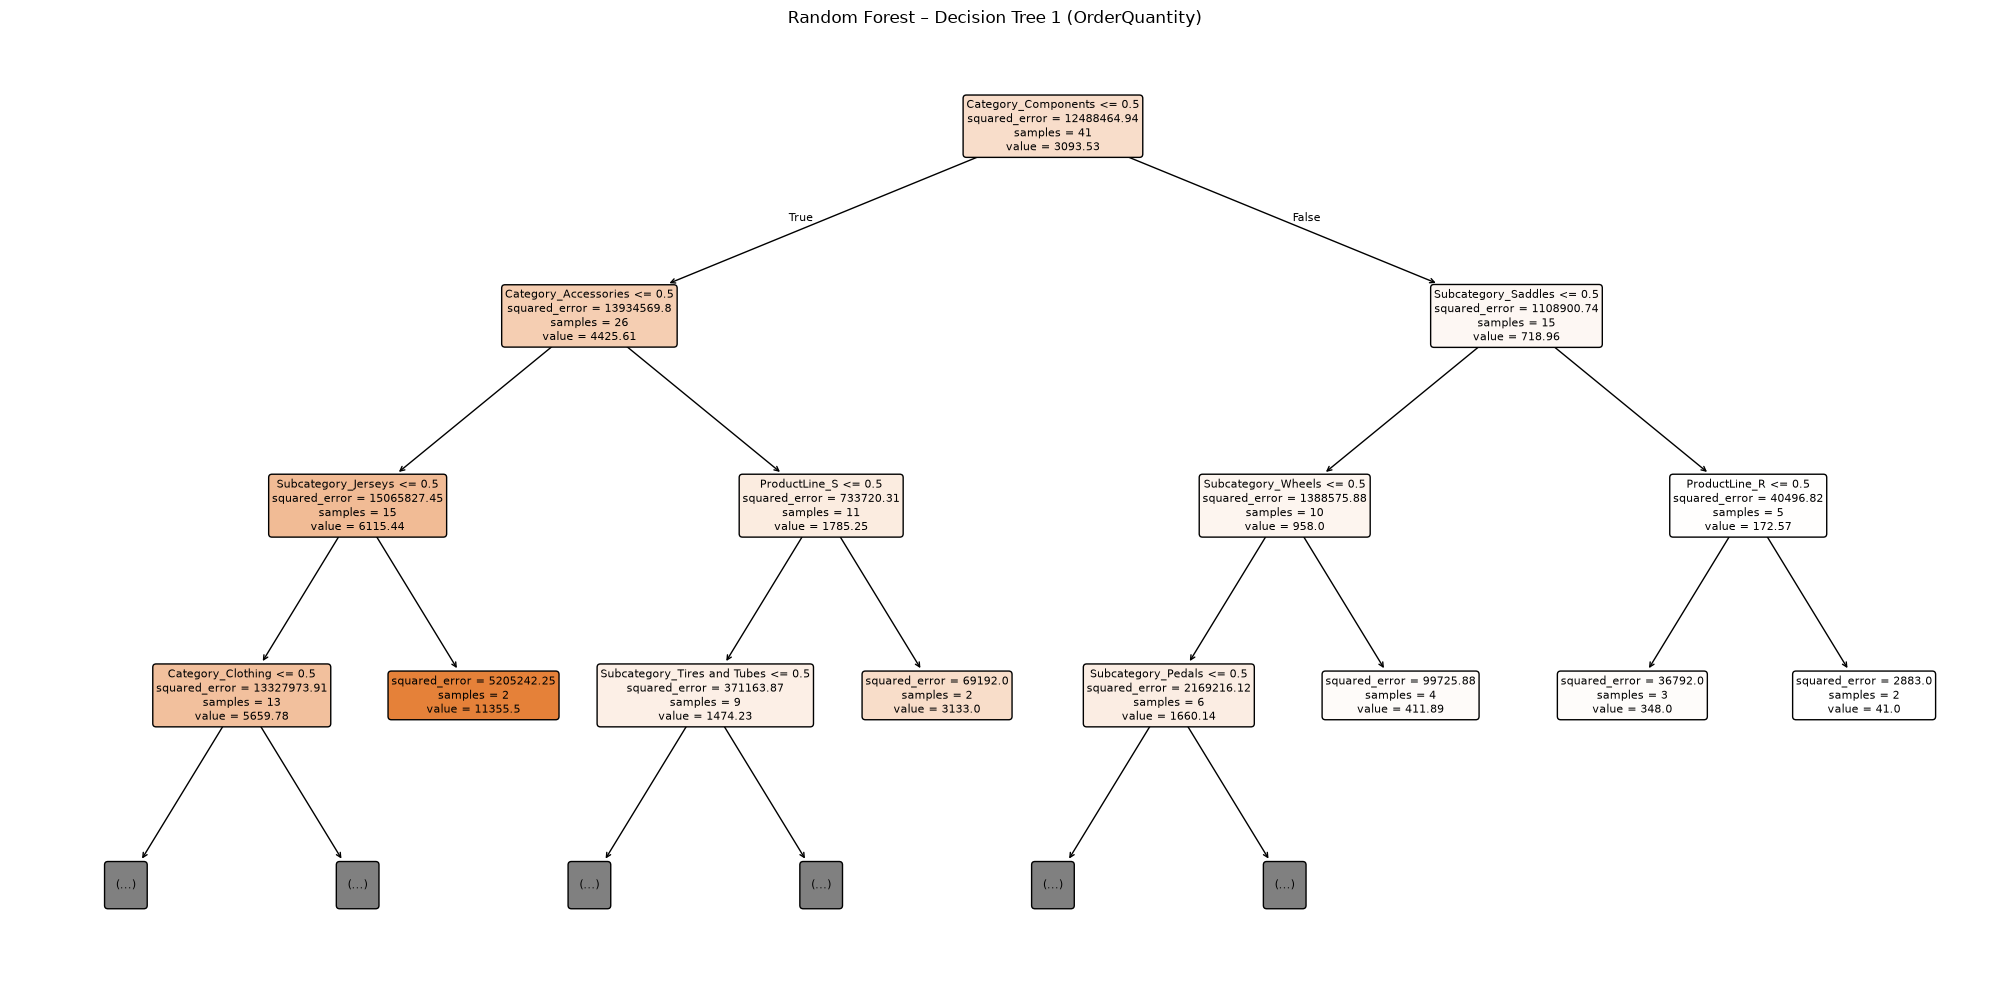

In [54]:
tree_model = best_model.best_model.estimators_[0]

fig = plt.figure(figsize=(20, 10))

_ = tree.plot_tree(
    tree_model,
    feature_names=X_train_enc.columns.tolist(),
    filled=True,
    rounded=True,
    precision=2,
    fontsize=8,
    max_depth=3,
)

plt.title("Random Forest – Decision Tree 1 (OrderQuantity)")
plt.tight_layout()
plt.show()

In [55]:
tree_model = best_model.best_model.estimators_[0]


print("Baumtiefe:", tree_model.get_depth())
print("Anzahl Blätter:", tree_model.get_n_leaves())
print("Pruning-Parameter:", tree_model.ccp_alpha)

Baumtiefe: 6
Anzahl Blätter: 15
Pruning-Parameter: 0.0


# Predictions

In [56]:
new_product = pd.DataFrame(
    [
        {
            "Category": "Bikes",
            "Subcategory": "Road Bikes",
            "ProductLine": "Road",
            "Model": "Road-150",
        }
    ]
)
new_product_enc = feature_engineer.transform(new_product)
prediction = best_model.predict(new_product_enc)[0]

print("Neues Produkt: Road-Racer")
print("Gewähltes Modell:", best_name)
print(f"Prognostizierte Bestellmenge: {prediction:.2f}")
print("Gerundete Prognose:", max(0, round(prediction)))

Neues Produkt: Road-Racer
Gewähltes Modell: Random Forest
Prognostizierte Bestellmenge: 6987.72
Gerundete Prognose: 6988


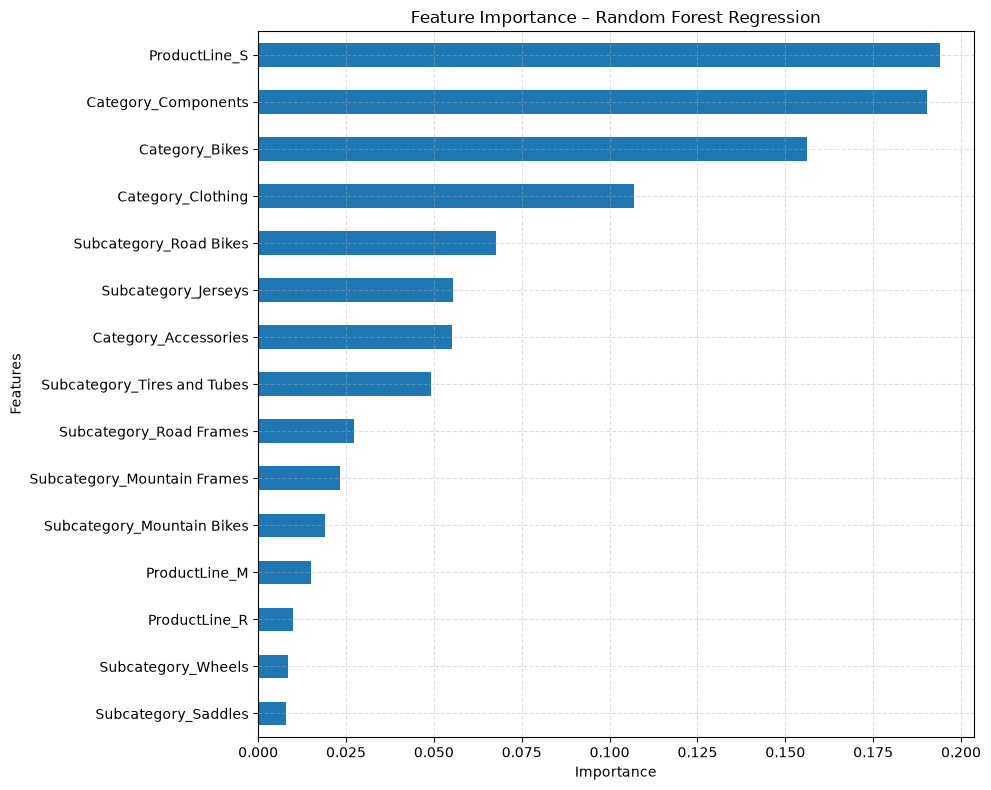

In [ ]:
tree_model = best_model.best_model

feature_importance = (
    pd.Series(tree_model.feature_importances_, index=X_train_enc.columns)
    .sort_values(ascending=True)
    .tail(15)
)

plt.figure(figsize=(10, 8))

feature_importance.plot(kind="barh")

plt.title("Feature Importance – Random Forest Regression")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.grid(alpha=0.4, linestyle="--")
plt.tight_layout()
plt.show()